# XGBoost detector for BATADAL

Supervised XGBoost after Nemade et al. (2026): 400 trees, depth 6, learning rate 0.05, 0.8 row/column subsampling, `scale_pos_weight` = negatives / positives; lag, difference and rolling features (no hour/weekday features by default: with them fewer attacks are caught; this choice was made on Dataset 2 results, so treat it as tuned. `--time-features` turns them back on).

**Labels.** Dataset 1 = normal (negatives). Dataset 2 `ATT_FLAG = 1` = attack hours (positives, 219 h). `ATT_FLAG = -999` rows are dropped: never a training or hour-level evaluation label (the ones inside a real attack window are scored only to measure detection delay).

**Protocol.** Leave-one-attack-out over the 5 attacks that have labeled hours; attacks 2 and 7 have none, so no model trains on them. Thresholds come from the calibration block (budget: <= 1 false-alarm episode/week and <= 1% of hours); false alarms are counted on the validation block. **Reporting.** No precision or F1: their true positives come from Dataset 2 and false positives from the validation block, so they only reflect the mix. The development tables give alarm hours per clean validation week; precision/F1 belong on the Test set. The S-score is the *approximate* one (recall and TNR come from different series). Episodes merge alarms at most 2 quiet hours apart (`MERGE_GAP_HOURS`, fixed for all detectors). AUC uses one fold model per clean hour (round-robin), like the hourly export. Dataset 2 normal hours (outside every attack window, minus 3 grace hours after each attack) are scored as an era check, with alarm share and episodes per week. Run from this folder (`models/XGBoost/`); needs `xgboost`, `pandas`, `numpy`, `matplotlib`.

In [1]:
import sys, json, pathlib, argparse
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
sys.path.insert(0, '.')
from xgb_data import load_blocks, WARMUP
from train_xgboost import run_seed, PAPER_PARAMS
from xgb_metrics import MERGE_GAP_HOURS, GRACE_HOURS
pd.set_option('display.width', 200)

DATA_DIR = pathlib.Path('../../data/processed')
OUT_DIR = pathlib.Path('notebook_outputs')
SEEDS = [0, 1, 2]

## 1. Data and features

In [2]:
blocks = load_blocks(str(DATA_DIR), time_features=False)
feats, meta = blocks['d2']
print('features:', blocks['train'][0].shape[1])
print({k: len(v[0]) for k, v in blocks.items()}, f'(first {WARMUP} rows of every block dropped)')
flag = meta.att_flag.value_counts().to_dict()
print('Dataset 2 ATT_FLAG counts:', flag)
per = meta[meta.attack_id > 0].groupby('attack_id').agg(real_hours=('att_flag', 'size'), labeled=('att_flag', lambda s: int((s == 1).sum())))
per

features: 387
{'train': 5233, 'val': 1705, 'cal': 1706, 'd2': 4154} (first 23 rows of every block dropped)
Dataset 2 ATT_FLAG counts: {-999: 3935, 1: 219}


,real_hours,labeled
attack_id,,
1,50,42
2,24,0
3,60,60
4,94,37
5,60,7
6,94,73
7,110,0


In [3]:
cols = list(blocks['train'][0].columns)
families = {'raw': [c for c in cols if not any(t in c for t in ('_lag', '_diff', '_r')) and not c.startswith(('hour_', 'dow_'))],
            'lag': [c for c in cols if '_lag' in c], 'diff': [c for c in cols if '_diff' in c],
            'rolling': [c for c in cols if '_r' in c and not c.startswith(('hour_', 'dow_'))],
            'time': [c for c in cols if c.startswith(('hour_', 'dow_'))]}
pd.Series({k: len(v) for k, v in families.items()}, name='columns')

raw         36
lag        108
diff        72
rolling    171
time         0
Name: columns, dtype: int64

## 2. Train, calibrate and evaluate (3 seeds)

Each seed trains one model per held-out attack plus a final model on all 219 positives.

In [4]:
args = argparse.Namespace(n_estimators=PAPER_PARAMS['n_estimators'], max_depth=PAPER_PARAMS['max_depth'],
                         learning_rate=PAPER_PARAMS['learning_rate'], n_jobs=-1,
                         max_alarm_fraction=0.01, max_episodes_per_week=1.0, merge_gap_hours=MERGE_GAP_HOURS, grace_hours=GRACE_HOURS,
                         time_features=False, label_rule='confirmed_only')
results = {}
for seed in SEEDS:
    metrics, per_attack = run_seed(blocks, args, str(OUT_DIR / f'seed{seed}'), seed)
    results[seed] = (metrics, pd.DataFrame(per_attack))
    print(f"seed {seed}: detected {metrics['attacks_detected']}/7, recall {metrics['recall']:.3f}, alarm h/wk {metrics['val_alarm_hours_per_week']:.2f}, ROC {metrics['roc_auc']:.3f}, PR {metrics['pr_auc']:.3f}, S~ {metrics['s_score_approx']:.3f}, D2-normal alarms {metrics['d2_clean_alarm_fraction']:.3f} ({metrics['d2_clean_episodes_per_week']:.2f} ep/wk)")

seed 0: detected 4/7, recall 0.292, alarm h/wk 1.48, ROC 0.696, PR 0.489, S~ 0.569, D2-normal alarms 0.016 (1.29 ep/wk)


seed 1: detected 6/7, recall 0.274, alarm h/wk 1.46, ROC 0.684, PR 0.482, S~ 0.618, D2-normal alarms 0.015 (1.02 ep/wk)


seed 2: detected 5/7, recall 0.265, alarm h/wk 1.48, ROC 0.696, PR 0.477, S~ 0.607, D2-normal alarms 0.015 (1.15 ep/wk)


## 3. Results

In [5]:
keys = ['attacks_detected', 'unseen_detected', 'mean_delay_hours', 'recall', 'recall_schedule', 'true_negative_rate', 'val_alarm_hours_per_week', 'val_false_alarm_episodes_per_week', 'd2_clean_alarm_fraction', 'd2_clean_episodes_per_week', 'roc_auc', 'pr_auc', 'roc_auc_schedule', 's_ttd', 's_clf', 's_score_approx']
table = pd.DataFrame({f'seed{s}': {k: m[k] for k in keys} for s, (m, _) in results.items()})
table['mean'] = table.mean(axis=1)
table.round(3)

,seed0,seed1,seed2,mean
attacks_detected,4.000,6.000,5.000,5.000
unseen_detected,1.000,2.000,1.000,1.333
mean_delay_hours,7.750,26.000,11.400,15.050
recall,0.292,0.274,0.265,0.277
recall_schedule,0.270,0.272,0.274,0.272
true_negative_rate,0.991,0.991,0.991,0.991
val_alarm_hours_per_week,1.478,1.462,1.478,1.473
val_false_alarm_episodes_per_week,0.854,0.854,0.805,0.838
d2_clean_alarm_fraction,0.016,0.015,0.015,0.015
d2_clean_episodes_per_week,1.292,1.015,1.154,1.154


In [6]:
results[0][1]

,attack,real_hours,labeled_hours,scored_by,threshold,detected,delay_hours,labeled_hours_alarmed,recall_on_labeled,window_hours_alarmed
0,1,50,42,fold1,0.004325,False,NaN,0,0.000000,0
1,2,24,0,final,0.015356,True,3.0,0,NaN,17
2,3,60,60,fold3,0.004171,True,10.0,28,0.466667,28
3,4,94,37,fold4,0.013721,True,10.0,36,0.972973,72
4,5,60,7,fold5,0.008730,True,8.0,0,0.000000,16
5,6,94,73,fold6,0.007949,False,NaN,0,0.000000,0
6,7,110,0,final,0.015356,False,NaN,0,NaN,0


`scored_by` shows which model scored each attack: a fold model that never saw that attack, or the final model for attacks 2 and 7 (no labeled hours). `d2_clean_alarm_fraction` is the share of Dataset 2 hours outside every attack window that alarm; it should sit near the 1% budget. A value far above it would mean the model reacts to the 2016 data, not to attacks.

In [7]:
pd.read_csv(OUT_DIR / 'seed0' / 'folds.csv').round(4)

,model,n_pos_train,threshold,n_extra_neg,cal_alarm_fraction,cal_episodes_per_week,val_alarm_fraction,val_episodes_per_week
0,fold1,177,0.0043,0,0.0088,0.9848,0.0053,0.7883
1,fold3,159,0.0042,0,0.0100,0.7878,0.0100,0.9853
2,fold4,182,0.0137,0,0.0088,0.9848,0.0106,1.0839
3,fold5,212,0.0087,0,0.0094,0.9848,0.0088,0.7883
4,fold6,146,0.0079,0,0.0100,0.8863,0.0100,0.6897
5,final,219,0.0154,0,0.0100,0.9848,0.0082,0.7883


## 4. Per-attack scores and feature importance (seed 0)

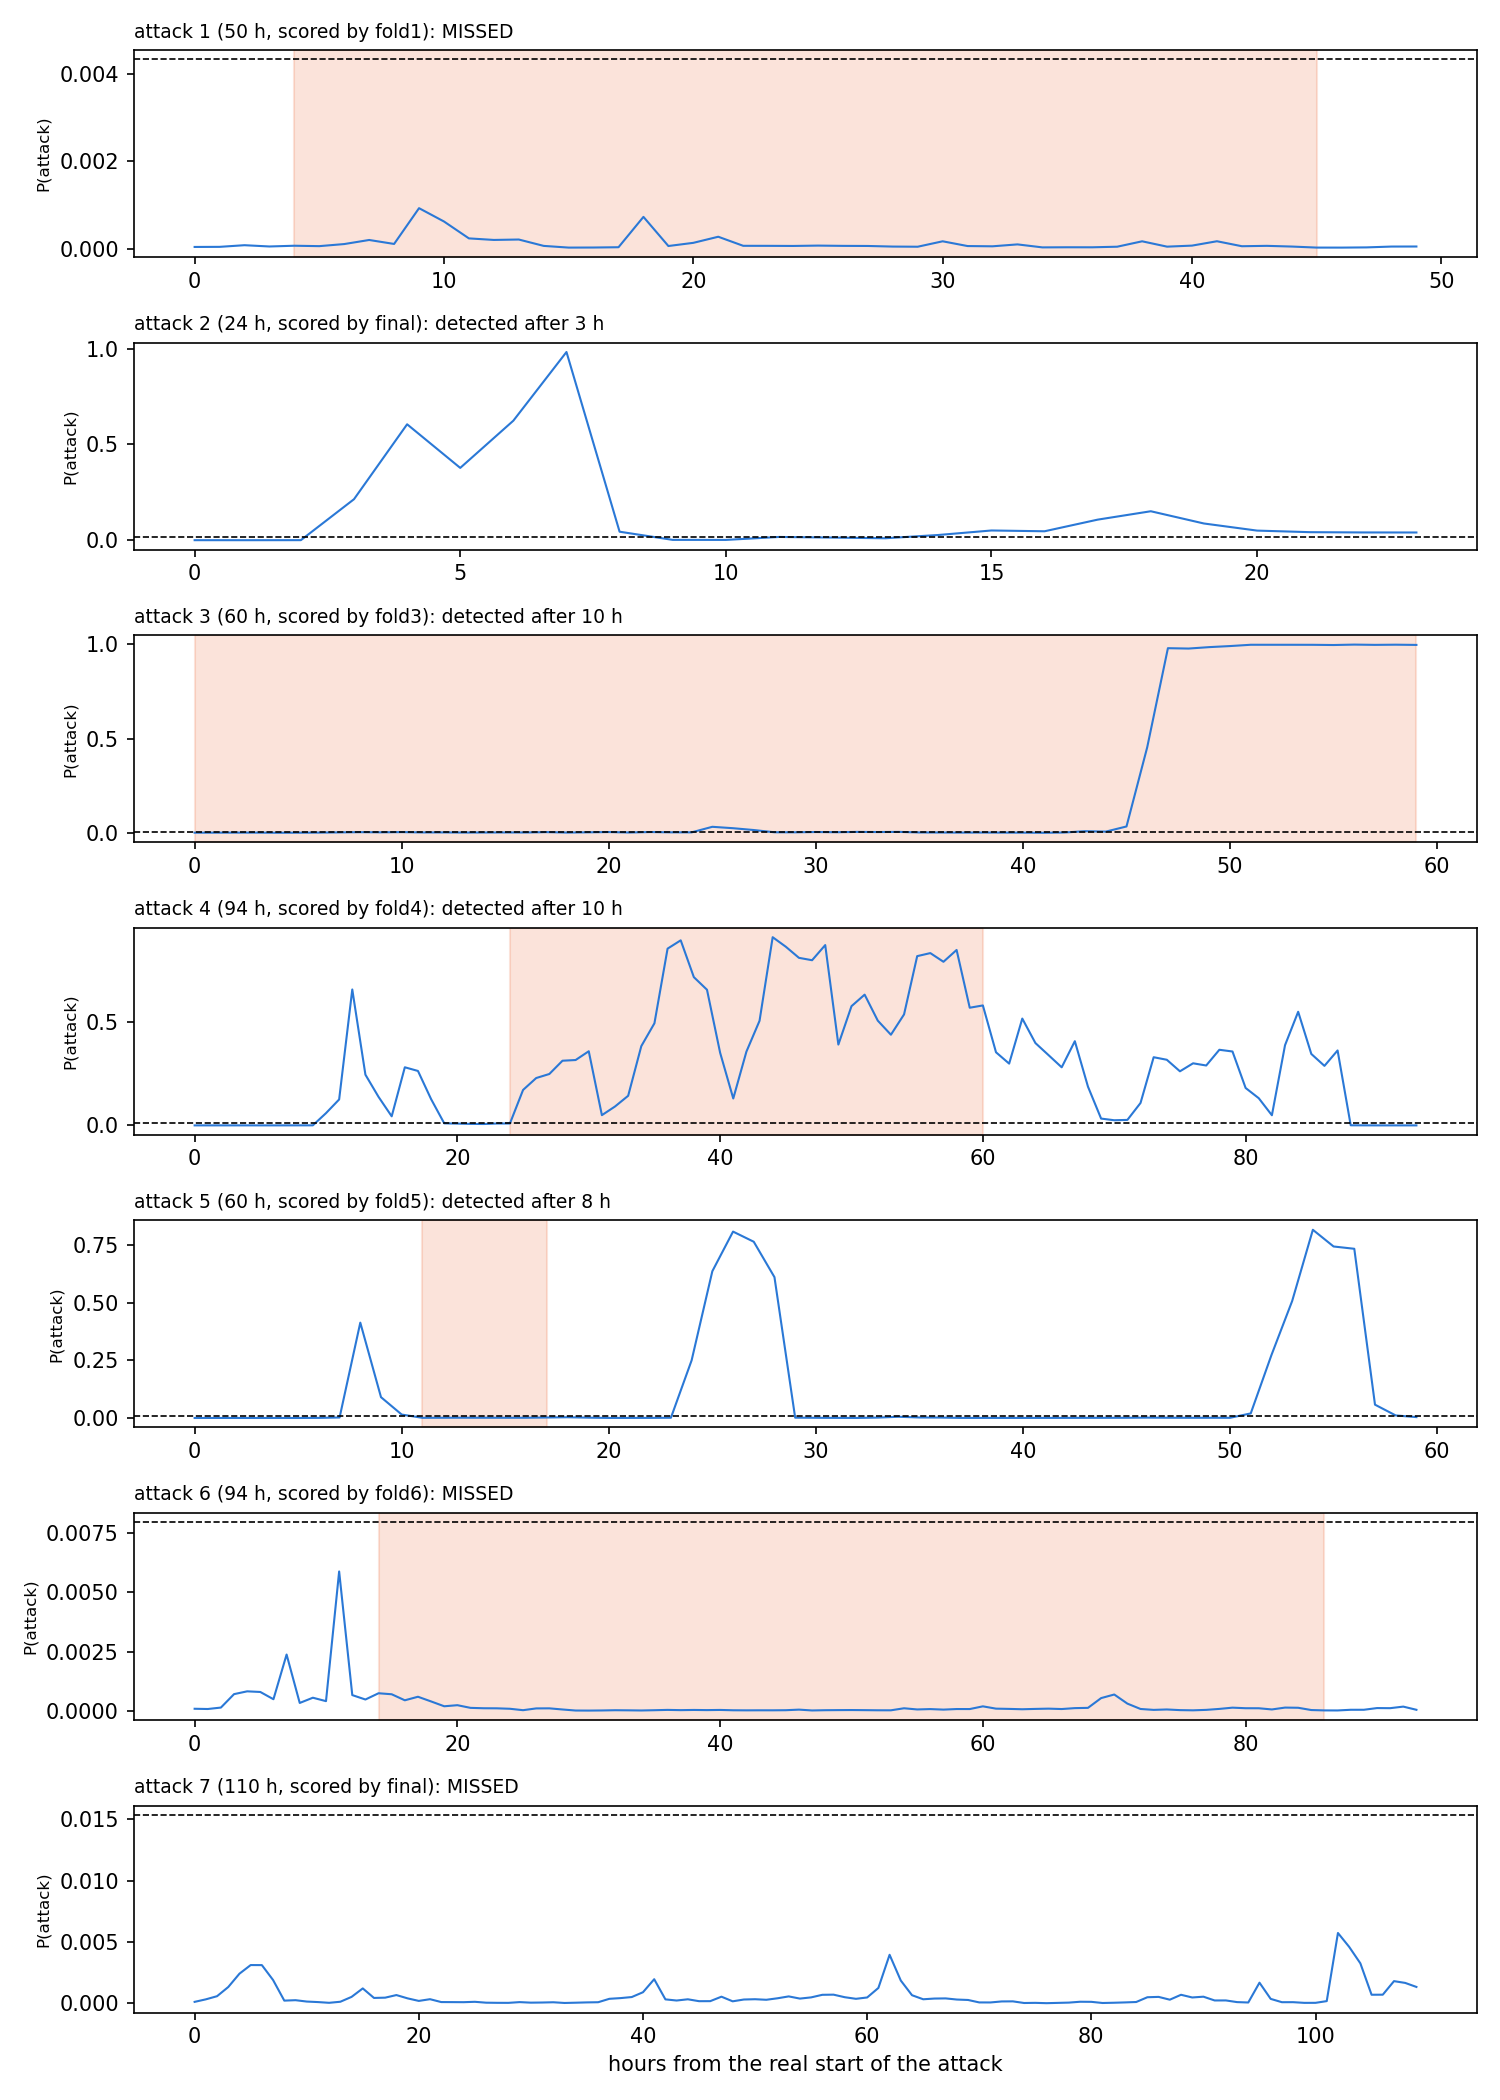

In [8]:
display(Image(str(OUT_DIR / 'seed0' / 'attack_scores.png')))

In [9]:
imp = pd.read_csv(OUT_DIR / 'seed0' / 'feature_importance.csv', index_col=0)['gain']
imp.head(20)[::-1].plot.barh(figsize=(6, 5), title='Top 20 features by gain (final model, seed 0)'); plt.tight_layout()
imp.groupby(lambda c: next((k for k, v in families.items() if c in v), 'other')).sum().div(imp.sum()).round(3).sort_values(ascending=False)

rolling    0.570
lag        0.246
raw        0.123
diff       0.062
Name: gain, dtype: float64

## 5. Era check and time features

Dataset 1 (negatives) is from 2014 and Dataset 2 (positives) from 2016. Scoring the Dataset 2 hours outside every attack window (never trained on under this label rule) shows whether the model is partly learning the year. The run with time features is read from `notebook_outputs/with_time_features/` (same protocol, `--time-features`).

In [10]:
TF_DIR = OUT_DIR / 'with_time_features'
blocks_t = load_blocks(str(DATA_DIR), time_features=True)
args_t = argparse.Namespace(**{**vars(args), 'time_features': True})
rows = {}
for s in SEEDS:
    m, _ = run_seed(blocks_t, args_t, str(TF_DIR / f'seed{s}'), s)
    rows[s] = m
cmp = pd.DataFrame({'no time features (default)': pd.DataFrame({s: {k: m[k] for k in keys} for s, (m, _) in results.items()}).mean(axis=1),
                    'with time features': pd.DataFrame({s: {k: rows[s][k] for k in keys} for s in SEEDS}).mean(axis=1)})
cmp.round(3)

,no time features (default),with time features
attacks_detected,5.000,4.000
unseen_detected,1.333,1.000
mean_delay_hours,15.050,10.917
recall,0.277,0.275
recall_schedule,0.272,0.251
true_negative_rate,0.991,0.994
val_alarm_hours_per_week,1.473,1.057
val_false_alarm_episodes_per_week,0.838,0.602
d2_clean_alarm_fraction,0.015,0.014
d2_clean_episodes_per_week,1.154,0.846


## 6. Label-rule sensitivity (the proposal's experiment)

XGBoost trained under three rules and evaluated on the same labels (confirmed `ATT_FLAG = 1` and the schedule, i.e. every hour of a real window). `confirmed_only` drops `-999`; `minus999_normal` treats every `-999` row as a clean negative (the paper's reading); `schedule` trains on every hour of every attack window, so the model also sees attack onsets. Under `schedule` no attack is held out of labels, so all 7 are leave-one-out. Under `minus999_normal` the Dataset 2 hours outside windows are trained on, so `d2_clean_alarm_fraction` is in-sample there and should not be read as an era check.

In [11]:
rule_rows = {'confirmed_only': pd.DataFrame({s: {k: m[k] for k in keys} for s, (m, _) in results.items()}).mean(axis=1)}
for rule in ('minus999_normal', 'schedule'):
    a = argparse.Namespace(**{**vars(args), 'label_rule': rule})
    ms = [run_seed(blocks, a, str(OUT_DIR / f'rule_{rule}' / f'seed{s}'), s)[0] for s in SEEDS]
    rule_rows[rule] = pd.DataFrame({i: {k: m[k] for k in keys} for i, m in enumerate(ms)}).mean(axis=1)
pd.DataFrame(rule_rows).round(3)

,confirmed_only,minus999_normal,schedule
attacks_detected,5.000,5.000,7.000
unseen_detected,1.333,1.000,0.000
mean_delay_hours,15.050,10.200,23.571
recall,0.277,0.256,0.623
recall_schedule,0.272,0.213,0.459
true_negative_rate,0.991,0.991,0.972
val_alarm_hours_per_week,1.473,1.456,4.664
val_false_alarm_episodes_per_week,0.838,0.991,1.600
d2_clean_alarm_fraction,0.015,0.007,0.026
d2_clean_episodes_per_week,1.154,0.846,1.676


## 7. Saved outputs

`notebook_outputs/seed<k>/`: `metrics.json`, `per_attack.csv`, `folds.csv`, `xgb_hourly_scores.csv` (input to `models/Ensemble/ensemble.py`), `feature_importance.csv/.png`, `attack_scores.png`, `final_model.json` (XGBoost model trained on all 219 positives).

In [12]:
sorted(p.name for p in (OUT_DIR / 'seed0').iterdir())

['attack_scores.png',
 'feature_importance.csv',
 'feature_importance.png',
 'final_model.json',
 'folds.csv',
 'metrics.json',
 'per_attack.csv',
 'xgb_hourly_scores.csv']